# Week 3 — 05: SHAP Interpretation

Compute SHAP values for both specialist models and compare their top features.


In [9]:
import sys, pathlib

# Resolve project root so notebooks work regardless of CWD or kernel launch dir
_this_nb  = pathlib.Path(__file__) if "__file__" in dir() else pathlib.Path().resolve()
_sentinel = "src"   # directory that marks the project root
_root     = _this_nb.resolve()
for _ in range(10):                          # walk up at most 10 levels
    if (_root / _sentinel).is_dir():
        break
    _root = _root.parent

# Hard-code fallback for direct kernel launch from notebooks/week3/
_fallback = pathlib.Path("/home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project")
if not (_root / _sentinel).is_dir():
    _root = _fallback

if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

PROJECT_ROOT = _root
print("Project root:", PROJECT_ROOT)


Project root: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project


In [10]:
from src import state
import numpy as np, pandas as pd
import shap, matplotlib.pyplot as plt
from src.config import SEED, PATTERN_BLOCKLIST_TOKENS

model_A, model_B = state.load("03_models")
(X, feature_cols, train_A_mask, val_A_mask, train_B_mask, val_B_mask,
 X_complete_val, X_complete_test, y_complete_test,
 train_base, val_base, test_base, patterned, unpatterned,
 train_idx, val_idx, test_idx) = state.load("03_matrices")
print(f"Models loaded. Features: {len(feature_cols)}")


Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_models.pkl
Loaded checkpoint: /home/malnaser/Eastnets-Standard-Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_matrices.pkl
Models loaded. Features: 139


In [11]:
bad = [c for c in feature_cols if any(t in c.lower() for t in PATTERN_BLOCKLIST_TOKENS)]
if bad:
    raise AssertionError(f"Pattern-derived features found: {bad}")
print(f"Feature count: {len(feature_cols)}  |  Safety check passed.")


Feature count: 139  |  Safety check passed.


In [12]:
SHAP_SAMPLE = 5000
rng = np.random.default_rng(SEED)

XA_val = X.loc[val_A_mask, feature_cols].copy()
XB_val = X.loc[val_B_mask, feature_cols].copy()

X_shap_A = XA_val.iloc[rng.choice(len(XA_val), size=min(SHAP_SAMPLE, len(XA_val)), replace=False)]
X_shap_B = XB_val.iloc[rng.choice(len(XB_val), size=min(SHAP_SAMPLE, len(XB_val)), replace=False)]
print(f"Model A SHAP rows: {len(X_shap_A):,}  |  Model B SHAP rows: {len(X_shap_B):,}")


Model A SHAP rows: 5,000  |  Model B SHAP rows: 5,000


In [13]:
explainer_A  = shap.TreeExplainer(model_A)
shap_vals_A  = explainer_A.shap_values(X_shap_A)
if isinstance(shap_vals_A, list): shap_vals_A = shap_vals_A[1]
shap_vals_A  = np.asarray(shap_vals_A)

importance_A = pd.DataFrame({"feature": feature_cols,
                               "mean_abs_shap": np.abs(shap_vals_A).mean(axis=0)
                              }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
print("Top 30 Model A features:")
print(importance_A.head(30).to_string())


Top 30 Model A features:
                             feature  mean_abs_shap
0            pair_velocity_x_veteran       0.946601
1                struct_random_score       0.832700
2                 struct_cycle_score       0.609453
3           new_pair_existing_sender       0.551442
4                 reverse_amount_gap       0.455491
5                   sender_delta_sec       0.452502
6                receiver_prev_count       0.355332
7             pair_velocity_relative       0.258312
8                 receiver_delta_sec       0.222286
9                   cluster_distance       0.218833
10                struct_stack_score       0.184591
11                            minute       0.153611
12                    pair_delta_sec       0.148619
13                receiver_unique_in       0.130527
14                   pair_prev_count       0.126368
15         paid_vs_receiver_mean_100       0.124128
16             corridor_share_sender       0.121583
17  sender_activity_shift_20_history   

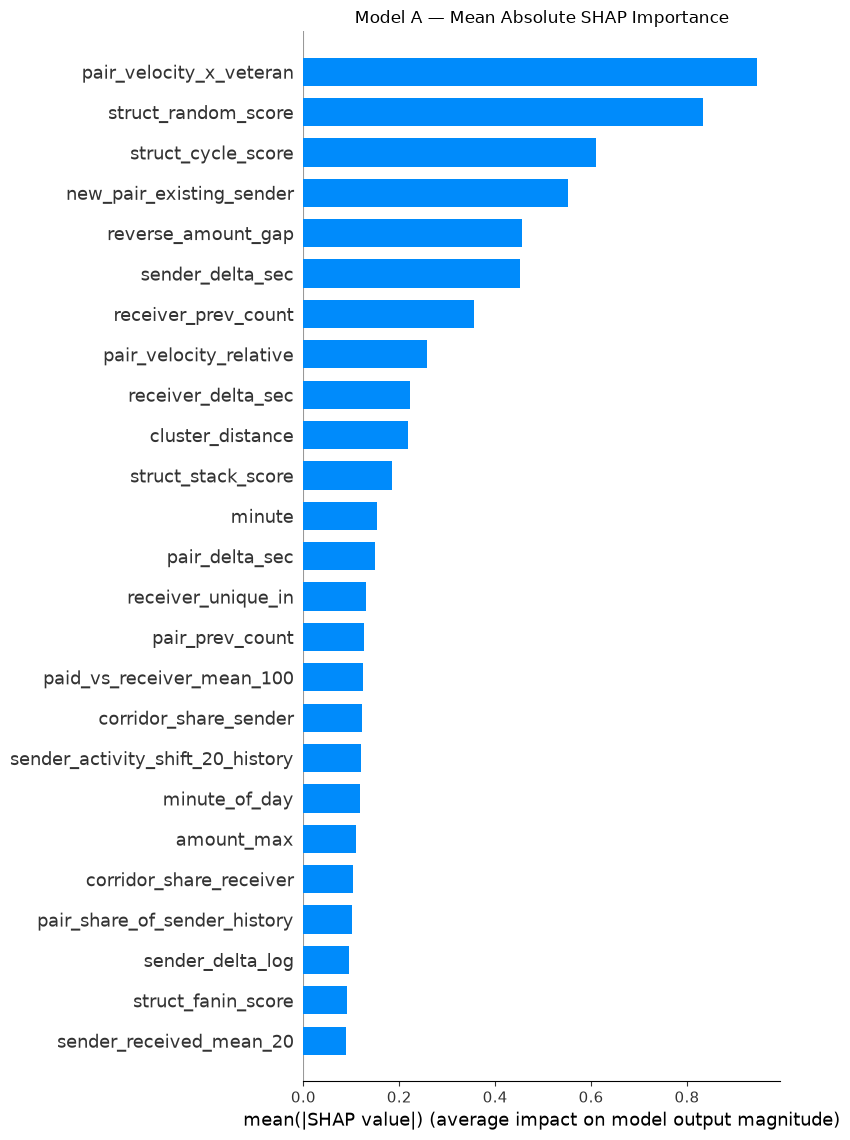

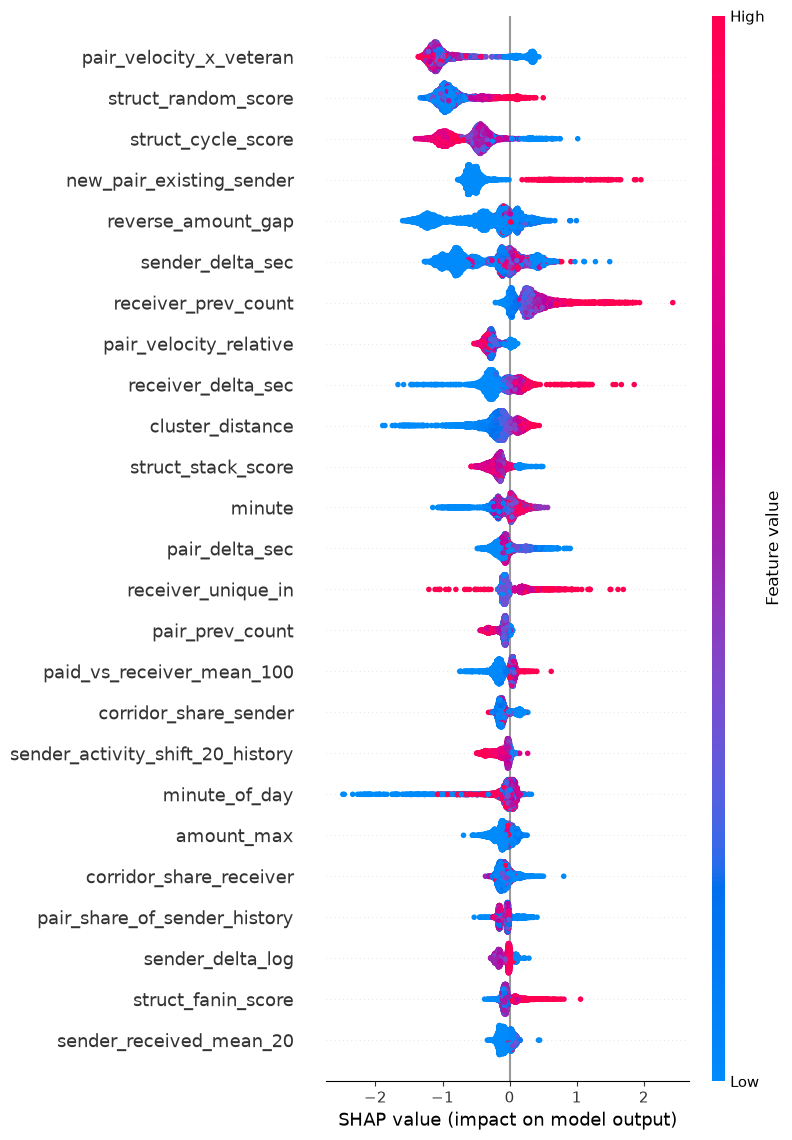

In [14]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_A, X_shap_A, plot_type="bar", max_display=25, show=False)
plt.title("Model A — Mean Absolute SHAP Importance"); plt.tight_layout(); plt.show()
shap.summary_plot(shap_vals_A, X_shap_A, max_display=25, show=True)


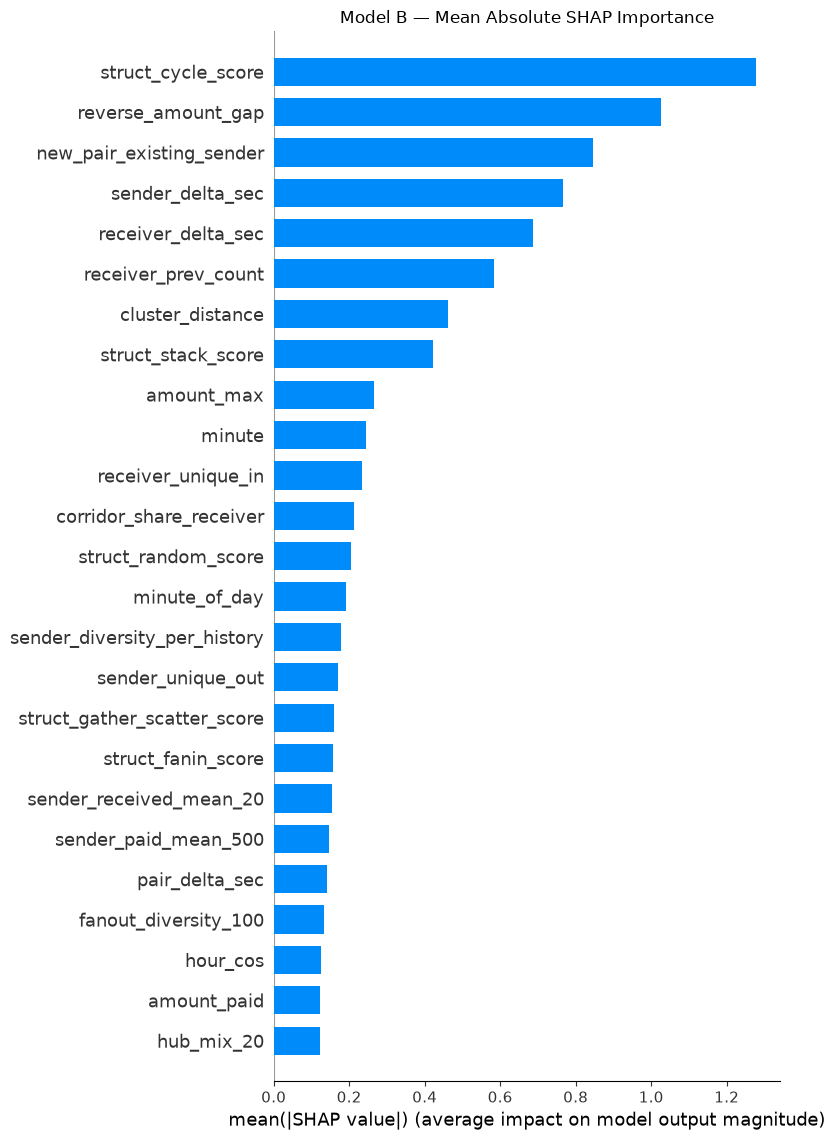

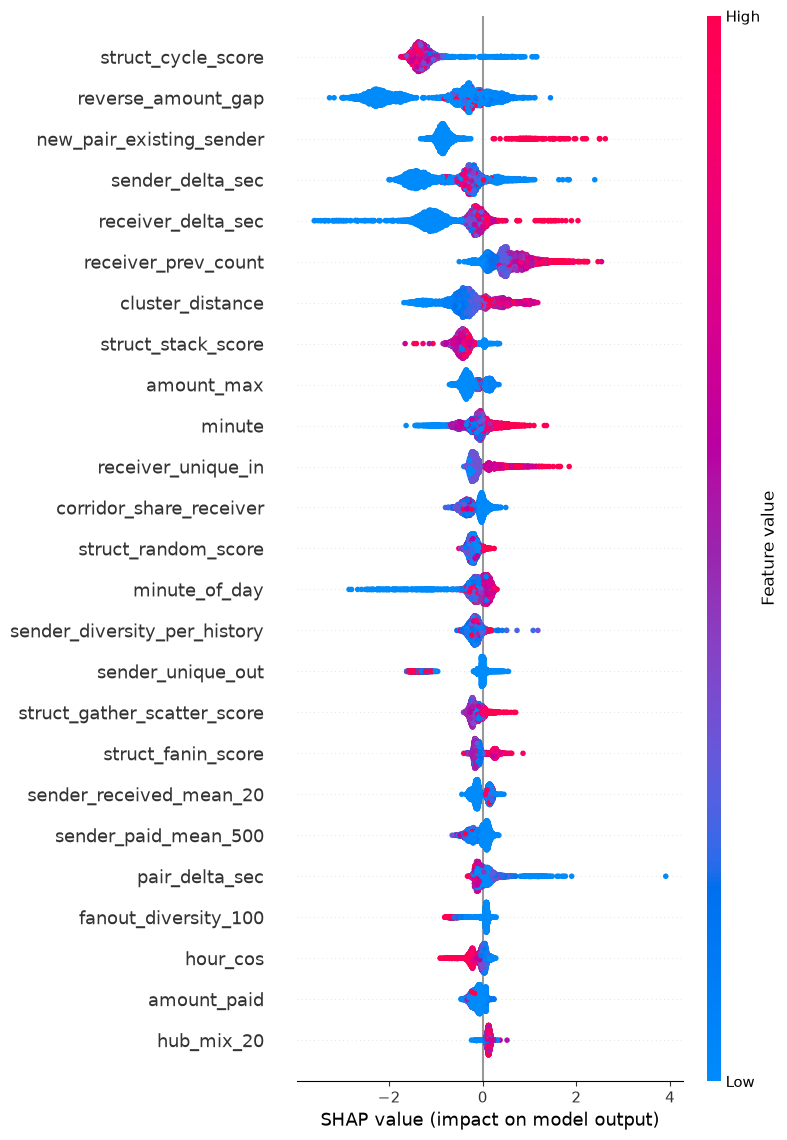

In [15]:
explainer_B  = shap.TreeExplainer(model_B)
shap_vals_B  = explainer_B.shap_values(X_shap_B)
if isinstance(shap_vals_B, list): shap_vals_B = shap_vals_B[1]
shap_vals_B  = np.asarray(shap_vals_B)

importance_B = pd.DataFrame({"feature": feature_cols,
                               "mean_abs_shap": np.abs(shap_vals_B).mean(axis=0)
                              }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_B, X_shap_B, plot_type="bar", max_display=25, show=False)
plt.title("Model B — Mean Absolute SHAP Importance"); plt.tight_layout(); plt.show()
shap.summary_plot(shap_vals_B, X_shap_B, max_display=25, show=True)


In [16]:
comparison = importance_A.merge(importance_B, on="feature", how="outer", suffixes=("_A","_B")).fillna(0)
comparison["diff_B_minus_A"] = comparison["mean_abs_shap_B"] - comparison["mean_abs_shap_A"]
comparison = comparison.sort_values("mean_abs_shap_A", ascending=False).reset_index(drop=True)
print(comparison.head(40).to_string())

state.save("05_shap", (importance_A, importance_B, comparison))
print("Checkpoint 05 saved.")


                             feature  mean_abs_shap_A  mean_abs_shap_B  diff_B_minus_A
0            pair_velocity_x_veteran         0.946601         0.015278       -0.931323
1                struct_random_score         0.832700         0.205523       -0.627177
2                 struct_cycle_score         0.609453         1.277267        0.667813
3           new_pair_existing_sender         0.551442         0.845200        0.293758
4                 reverse_amount_gap         0.455491         1.026877        0.571386
5                   sender_delta_sec         0.452502         0.765826        0.313324
6                receiver_prev_count         0.355332         0.583878        0.228546
7             pair_velocity_relative         0.258312         0.017219       -0.241093
8                 receiver_delta_sec         0.222286         0.686812        0.464526
9                   cluster_distance         0.218833         0.460965        0.242132
10                struct_stack_score       